In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse.linalg import svds

# Task 1

In [2]:
def my_svd(A):
    eigvals, V = np.linalg.eigh(A.T @ A)
    idx = np.argsort(eigvals)[::-1]
    eigvals = eigvals[idx]
    V = V[:, idx]
    sigma = np.sqrt(eigvals[eigvals > 1e-10])
    r = len(sigma)
    U = A @ V[:, :r] / sigma
    Sigma = np.diag(sigma)
    Vt = V[:, :r].T
    return U, Sigma, Vt

In [3]:
A = np.array([[3, 2, 2],
              [2, 3, -2]], dtype=float)

In [4]:
U, Sigma, Vt = my_svd(A)
print("U:\n", np.round(U, 4))
print("\nSigma:\n", np.round(Sigma, 4))
print("\nVt:\n", np.round(Vt, 4))
print("\nU @ Sigma @ Vt:\n", np.round(U @ Sigma @ Vt, 4))
print("\nEqual to A:", np.allclose(A, U @ Sigma @ Vt))

U:
 [[-0.7071  0.7071]
 [-0.7071 -0.7071]]

Sigma:
 [[5. 0.]
 [0. 3.]]

Vt:
 [[-0.7071 -0.7071 -0.    ]
 [ 0.2357 -0.2357  0.9428]]

U @ Sigma @ Vt:
 [[ 3.  2.  2.]
 [ 2.  3. -2.]]

Equal to A: True


In [5]:
B = np.random.randint(-5, 6, size=(4, 3)).astype(float)
U, Sigma, Vt = my_svd(B)
print("B:\n", B)
print("\nU @ Sigma @ Vt:\n", np.round(U @ Sigma @ Vt, 4))
print("\nEqual to B:", np.allclose(B, U @ Sigma @ Vt))

B:
 [[-2. -3. -4.]
 [-2. -3.  2.]
 [ 3.  5.  3.]
 [-2.  1.  4.]]

U @ Sigma @ Vt:
 [[-2. -3. -4.]
 [-2. -3.  2.]
 [ 3.  5.  3.]
 [-2.  1.  4.]]

Equal to B: True


# Task 2. Part 1

In [6]:
file_path = 'ratings.csv'
df = pd.read_csv(file_path)
df.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [7]:
ratings_matrix = df.pivot(index='userId', columns='movieId', values='rating')
print(ratings_matrix.shape)
ratings_matrix.head()

(610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Number of ratings:", len(df))
print("Number of users:", df['userId'].nunique())
print("Number of movies:", df['movieId'].nunique())
print("Filled cells, %:", round(ratings_matrix.notna().values.mean() * 100, 2))

Number of ratings: 100836
Number of users: 610
Number of movies: 9724
Filled cells, %: 1.7


In [9]:
print(df['rating'].value_counts().sort_index())

rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


In [10]:
print("Ratings per user:\n", ratings_matrix.notna().sum(axis=1).describe())
print("\nRatings per movie:\n", ratings_matrix.notna().sum(axis=0).describe())

Ratings per user:
 count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

Ratings per movie:
 count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64


In [11]:
ratings_matrix = ratings_matrix.dropna(thresh=100, axis=0)
ratings_matrix = ratings_matrix.dropna(thresh=50, axis=1)
print(ratings_matrix.shape)
print("Filled cells, %:", round(ratings_matrix.notna().values.mean() * 100, 2))

(248, 334)
Filled cells, %: 31.83


In [12]:
ratings_matrix_filled = ratings_matrix.fillna(2.5)
R = ratings_matrix_filled.values
user_ratings_mean = np.mean(R, axis=1)
R_demeaned = R - user_ratings_mean.reshape(-1, 1)
print(R_demeaned.shape)

(248, 334)


In [13]:
U, sigma, Vt = svds(R_demeaned, k=3)
print("U:", U.shape)
print("sigma:", np.round(sigma, 2))
print("Vt:", Vt.shape)

U: (248, 3)
sigma: [45.79 53.48 75.85]
Vt: (3, 334)


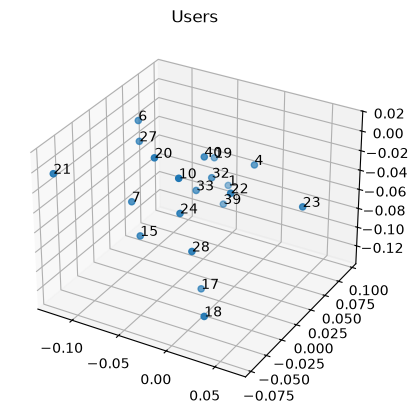

In [14]:
n = 20
ax = plt.figure().add_subplot(projection='3d')
ax.scatter(U[:n, 0], U[:n, 1], U[:n, 2])
for i in range(n):
    ax.text(U[i, 0], U[i, 1], U[i, 2], ratings_matrix.index[i])
ax.set_title("Users")
plt.show()

In [15]:
movies = pd.read_csv('movies.csv')
titles = movies.set_index('movieId').loc[ratings_matrix.columns, 'title']

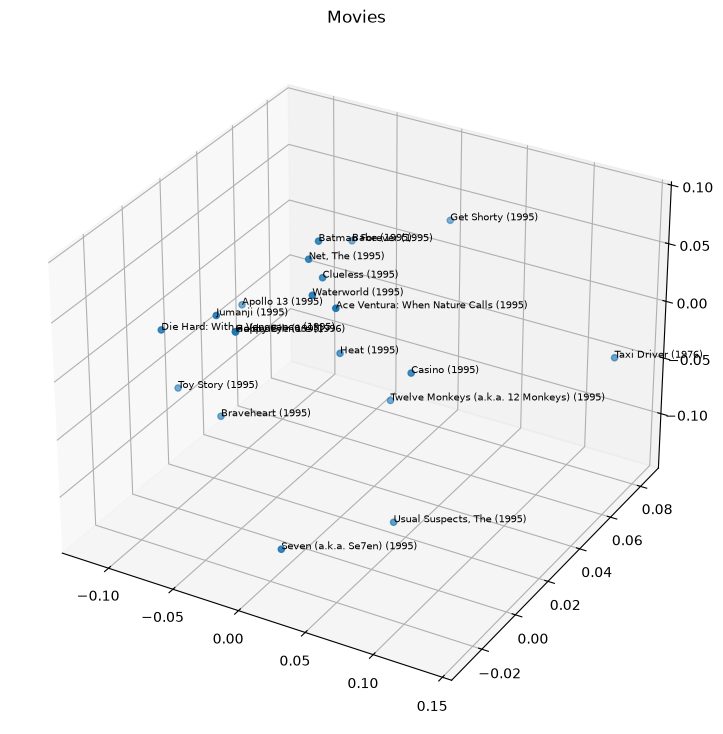

In [16]:
ax = plt.figure(figsize=(12, 9)).add_subplot(projection='3d')
ax.scatter(Vt[0, :n], Vt[1, :n], Vt[2, :n])
for i in range(n):
    ax.text(Vt[0, i], Vt[1, i], Vt[2, i], titles.iloc[i], fontsize=7)
ax.set_title("Movies")
plt.show()

# Task 2. Part 2

In [17]:
ratings_matrix = df.pivot(index='userId', columns='movieId', values='rating')
ratings_matrix = ratings_matrix.dropna(thresh=50, axis=0)
ratings_matrix = ratings_matrix.dropna(thresh=20, axis=1)
print(ratings_matrix.shape)
print("Filled cells, %:", round(ratings_matrix.notna().values.mean() * 100, 2))

(385, 1247)
Filled cells, %: 12.72


In [18]:
ratings_matrix_filled = ratings_matrix.fillna(2.5)
R = ratings_matrix_filled.values
user_ratings_mean = np.mean(R, axis=1)
R_demeaned = R - user_ratings_mean.reshape(-1, 1)
print(R_demeaned.shape)

(385, 1247)


In [19]:
k = 10
U, sigma, Vt = svds(R_demeaned, k=k)
sigma = np.diag(sigma)
all_user_predicted_ratings = np.dot(np.dot(U, sigma), Vt) + user_ratings_mean.reshape(-1, 1)
preds_df = pd.DataFrame(all_user_predicted_ratings, columns=ratings_matrix.columns, index=ratings_matrix.index)
preds_df.head()

movieId,1,2,3,5,6,7,10,11,16,17,...,122918,122920,134130,134853,139385,148626,152081,164179,166528,168252
userId,,,,,,,,,,,,,,,,,,,,,
1,3.894687,2.839920,2.912454,2.671196,3.068175,2.487021,3.106974,2.584844,3.089187,2.142008,...,2.514327,2.606232,2.593434,2.489944,2.646219,2.598265,2.488022,2.538386,2.567866,2.469755
4,3.475647,2.571765,2.572335,2.523097,2.396555,2.448697,2.415350,2.597241,2.538121,2.861956,...,2.485176,2.476960,2.443338,2.530994,2.410974,2.536575,2.485697,2.472438,2.392830,2.401926
6,3.926182,3.816541,3.292034,3.173308,3.423389,3.335801,3.500197,3.736276,2.977506,3.185782,...,2.479032,2.528760,2.433031,2.497225,2.449908,2.514473,2.502737,2.492738,2.412627,2.480616
7,3.461977,2.809482,2.394868,2.432511,2.857009,2.470174,2.945106,2.642771,2.480013,2.716099,...,2.610263,2.581982,2.405669,2.643736,2.353825,2.353609,2.625418,2.495884,2.669453,2.614245
10,2.699071,2.661697,2.443826,2.478715,2.399085,2.538926,2.543806,2.611267,2.310792,2.697019,...,2.640997,2.588856,2.621916,2.669993,2.535681,2.536566,2.645372,2.576175,2.664408,2.650583


In [20]:
user_ratings = ratings_matrix.loc[1].dropna()
comparison = pd.DataFrame({'real': user_ratings, 'predicted': preds_df.loc[1, user_ratings.index]})
comparison.head(10)

,real,predicted
movieId,,
1,4.0,3.894687
3,4.0,2.912454
6,4.0,3.068175
47,5.0,3.759935
50,5.0,3.905075
70,3.0,3.040342
101,5.0,2.976244
110,4.0,3.961448
151,5.0,2.624481


In [21]:
mask = ratings_matrix.notna().values
known = ratings_matrix.values[mask]
for k in [2, 5, 10, 20, 50, 100, 300]:
    U_k, sigma_k, Vt_k = svds(R_demeaned, k=k)
    pred = U_k @ np.diag(sigma_k) @ Vt_k + user_ratings_mean.reshape(-1, 1)
    rmse = np.sqrt(np.mean((pred[mask] - known) ** 2))
    print(f"k = {k}: RMSE = {rmse:.3f}, spread of predictions for unrated = {pred[~mask].std():.3f}")

k = 2: RMSE = 1.164, spread of predictions for unrated = 0.165
k = 5: RMSE = 1.087, spread of predictions for unrated = 0.181
k = 10: RMSE = 1.019, spread of predictions for unrated = 0.190
k = 20: RMSE = 0.936, spread of predictions for unrated = 0.194
k = 50: RMSE = 0.761, spread of predictions for unrated = 0.193
k = 100: RMSE = 0.553, spread of predictions for unrated = 0.176
k = 300: RMSE = 0.109, spread of predictions for unrated = 0.066


In [22]:
fills = {'0': ratings_matrix.fillna(0),
         '2.5': ratings_matrix.fillna(2.5),
         'user mean': ratings_matrix.apply(lambda row: row.fillna(row.mean()), axis=1)}
for name, filled in fills.items():
    R_f = filled.values
    mean_f = np.mean(R_f, axis=1).reshape(-1, 1)
    U_f, sigma_f, Vt_f = svds(R_f - mean_f, k=10)
    pred = U_f @ np.diag(sigma_f) @ Vt_f + mean_f
    rmse = np.sqrt(np.mean((pred[mask] - known) ** 2))
    print(f"fill = {name}: RMSE = {rmse:.3f}, mean prediction for unrated = {pred[~mask].mean():.2f}")

fill = 0: RMSE = 2.217, mean prediction for unrated = 0.26
fill = 2.5: RMSE = 1.019, mean prediction for unrated = 2.58
fill = user mean: RMSE = 0.766, mean prediction for unrated = 3.69


In [23]:
preds_only = preds_df.where(ratings_matrix.isna())
preds_only.head()

movieId,1,2,3,5,6,7,10,11,16,17,...,122918,122920,134130,134853,139385,148626,152081,164179,166528,168252
userId,,,,,,,,,,,,,,,,,,,,,
1,NaN,2.839920,NaN,2.671196,NaN,2.487021,3.106974,2.584844,3.089187,2.142008,...,2.514327,2.606232,2.593434,2.489944,2.646219,2.598265,2.488022,2.538386,2.567866,2.469755
4,3.475647,2.571765,2.572335,2.523097,2.396555,2.448697,2.415350,2.597241,2.538121,2.861956,...,2.485176,2.476960,2.443338,2.530994,2.410974,2.536575,2.485697,2.472438,2.392830,2.401926
6,3.926182,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2.479032,2.528760,2.433031,2.497225,2.449908,2.514473,2.502737,2.492738,2.412627,2.480616
7,NaN,2.809482,2.394868,2.432511,2.857009,2.470174,2.945106,2.642771,2.480013,2.716099,...,2.610263,2.581982,2.405669,2.643736,2.353825,2.353609,2.625418,2.495884,2.669453,2.614245
10,2.699071,2.661697,2.443826,2.478715,2.399085,2.538926,2.543806,2.611267,2.310792,2.697019,...,2.640997,2.588856,2.621916,2.669993,2.535681,2.536566,2.645372,2.576175,2.664408,2.650583


In [24]:
def recommend_movies(user_id, n=10):
    top = preds_only.loc[user_id].sort_values(ascending=False).head(n)
    return movies.set_index('movieId').loc[top.index, ['title', 'genres']]

In [25]:
recommend_movies(1)

,title,genres
movieId,,
589,Terminator 2: Judgment Day (1991),Action|Sci-Fi
1200,Aliens (1986),Action|Adventure|Horror|Sci-Fi
1968,"Breakfast Club, The (1985)",Comedy|Drama
2918,Ferris Bueller's Day Off (1986),Comedy
1036,Die Hard (1988),Action|Crime|Thriller
2683,Austin Powers: The Spy Who Shagged Me (1999),Action|Adventure|Comedy
2762,"Sixth Sense, The (1999)",Drama|Horror|Mystery
32,Twelve Monkeys (a.k.a. 12 Monkeys) (1995),Mystery|Sci-Fi|Thriller
1259,Stand by Me (1986),Adventure|Drama


In [26]:
recommend_movies(6)

,title,genres
movieId,,
1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
648,Mission: Impossible (1996),Action|Adventure|Mystery|Thriller
300,Quiz Show (1994),Drama
442,Demolition Man (1993),Action|Adventure|Sci-Fi
733,"Rock, The (1996)",Action|Adventure|Thriller
223,Clerks (1994),Comedy
48,Pocahontas (1995),Animation|Children|Drama|Musical|Romance
39,Clueless (1995),Comedy|Romance
551,"Nightmare Before Christmas, The (1993)",Animation|Children|Fantasy|Musical


In [27]:
recommend_movies(7)

,title,genres
movieId,,
1198,Raiders of the Lost Ark (Indiana Jones and the...,Action|Adventure
2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller
318,"Shawshank Redemption, The (1994)",Crime|Drama
364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX
1291,Indiana Jones and the Last Crusade (1989),Action|Adventure
5418,"Bourne Identity, The (2002)",Action|Mystery|Thriller
1580,Men in Black (a.k.a. MIB) (1997),Action|Comedy|Sci-Fi
4226,Memento (2000),Mystery|Thriller
6377,Finding Nemo (2003),Adventure|Animation|Children|Comedy
